# 04 · Mapa y gráficos principales

Visual obligatorio de la ruta: un mapa de separación por distrito, acompañado de barras (para comparar valores con precisión) y de la serie mensual.

In [1]:
from pathlib import Path
import pandas as pd

# Carpeta del proyecto (funciona si el notebook se abre desde la raíz o desde notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
OUT = ROOT / 'data' / 'processed'
FIG = ROOT / 'docs' / 'figures'
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLOR = {'basura': '#2a78d6', 'papel': '#eb6834', 'mgp': '#1baf7a'}
NOMBRE = {'basura': 'Basura común', 'papel': 'Papel', 'mgp': 'MGP'}
import geopandas as gpd

df = pd.read_csv(OUT / 'residuos_mensuales.csv', parse_dates=['month'])
mapa = gpd.read_file(OUT / 'distritos_indicadores.geojson')
MES = '2026-09-01'  # último mes completo
fracciones = ['basura', 'papel', 'mgp']

## Mapa de separación
Escala secuencial (viridis): a más claro, mayor proporción de papel y MGP. El gris indica áreas sin datos, no un valor cero.

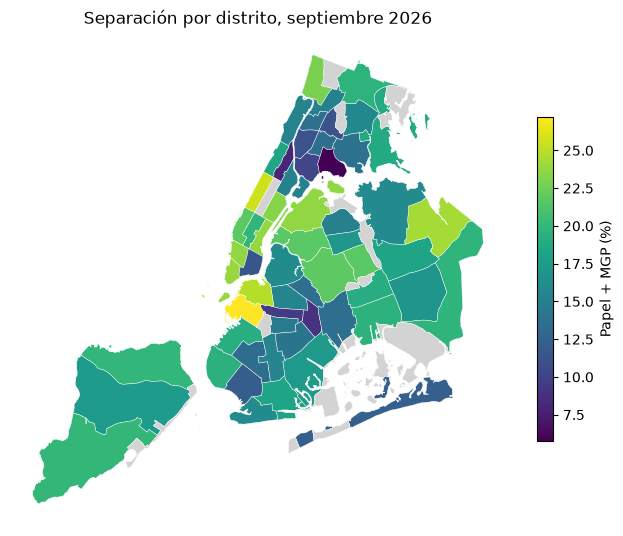

In [2]:
fig, ax = plt.subplots(figsize=(8, 7))
mapa.plot(column='separacion_pct', cmap='viridis', legend=True, ax=ax,
          edgecolor='white', linewidth=0.3, missing_kwds={'color': 'lightgray'},
          legend_kwds={'label': 'Papel + MGP (%)', 'shrink': 0.6})
ax.set_axis_off()
ax.set_title('Separación por distrito, septiembre 2026')
plt.savefig(FIG / 'mapa_separacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Distritos con menor separación

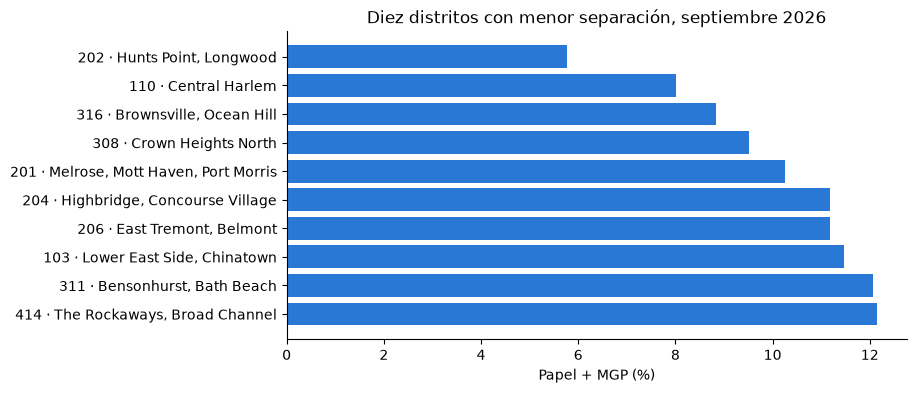

In [3]:
ultimo = df[df['month'] == MES].sort_values('separacion_pct').head(10)
etiquetas = ultimo['boro_cd'].astype(str) + ' · ' + ultimo['nombre']

plt.figure(figsize=(8, 4))
plt.barh(etiquetas, ultimo['separacion_pct'], color='#2a78d6')
plt.gca().invert_yaxis()
plt.xlabel('Papel + MGP (%)')
plt.title('Diez distritos con menor separación, septiembre 2026')
plt.savefig(FIG / 'comparacion_distritos.png', dpi=150, bbox_inches='tight')
plt.show()

## Evolución mensual

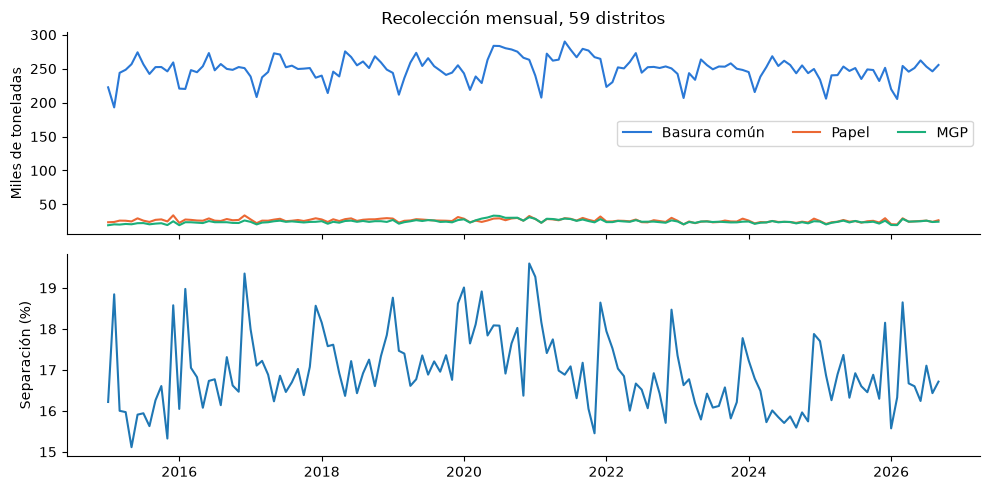

In [4]:
mensual = df.groupby('month')[fracciones].sum()
mensual['separacion_pct'] = 100 * (mensual['papel'] + mensual['mgp']) / mensual[fracciones].sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for c in fracciones:
    axes[0].plot(mensual.index, mensual[c] / 1000, color=COLOR[c], label=NOMBRE[c])
axes[0].set_ylabel('Miles de toneladas')
axes[0].legend(ncol=3)
axes[1].plot(mensual.index, mensual['separacion_pct'])
axes[1].set_ylabel('Separación (%)')
axes[0].set_title('Recolección mensual, 59 distritos')
plt.tight_layout()
plt.savefig(FIG / 'serie_mensual.png', dpi=150)
plt.show()

## Distritos a revisar
Criterio exploratorio: distritos que están a la vez en el 25 % con **más basura común** y en el 25 % con **menor separación** del mismo mes. No es una norma ni prueba un mal servicio; sirve para decidir dónde mirar primero.

In [5]:
ultimo = df[df['month'] == MES].copy()
mucha_basura = ultimo['basura'] >= ultimo['basura'].quantile(0.75)
poca_separacion = ultimo['separacion_pct'] <= ultimo['separacion_pct'].quantile(0.25)
ultimo['prioridad'] = mucha_basura & poca_separacion

ultimo.to_csv(OUT / 'comparacion_ultimo_mes.csv', index=False)
ultimo[ultimo['prioridad']][['boro_cd', 'BOROUGH', 'nombre', 'basura', 'separacion_pct']].round(1)

,boro_cd,BOROUGH,nombre,basura,separacion_pct
1,202,Bronx,"Hunts Point, Longwood",8050.7,5.8
16,305,Brooklyn,"East New York, Starrett City",5021.4,13.4
19,308,Brooklyn,Crown Heights North,6322.8,9.5
22,311,Brooklyn,"Bensonhurst, Bath Beach",7807.3,12.1
23,312,Brooklyn,"Borough Park, Ocean Parkway",7611.0,13.4
32,103,Manhattan,"Lower East Side, Chinatown",6320.0,11.5
39,110,Manhattan,Central Harlem,6411.0,8.0
